<H1> Loop Antenna </H1> 
First using engineering equations and then proceeding to using first principles can you predict the
performance and field of a small circular antenna. 

This is based on a conversation I had with Paul regarding wanting to model this antenna in Comsol. My point of view is that
you should roughly know the answer on the back of the envelope prior to starting.

<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 07-Oct-25 </td>
        <td> CBL </td> 
        <td> ORIGINAL </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
<a href="https://www.66pacific.com/calculators/small-transmitting-loop-antenna-calculator.aspx"> full wave loop antenna </a> <br>
<a href="https://www.electronics-tutorials.ws/tools/coil-inductance-calculator.html"> Inductance of loop </a> <br> 
<a href="https://coil32.net/single-loop-of-wire.html"> Another inductance of single loop of wire </a><br> 
<a href="https://www.thompsonrd.com/induct2.pdf"> derivation from Inductance Calculations by Grover </a>
<hr> 
other useful resources for doing inductance and capacitance calculations:<br> 
<a href="https://www.fastfieldsolvers.com/fastcap2.htm"> FastCap Fast field solver</a><br> 
<a href="https://www.fastfieldsolvers.com/fasthenry2.htm"> Fast Henry fast field solver</a><br> 


<H2> Notes </H2>
All antennas are essentially resonant circuits. The intrinsic impedance should be ${Z_0} = \sqrt{{L\over{C}}}$
<br>

In [1]:
# python imports used in this demonstration. 
import numpy as np
import matplotlib.pyplot as plt
# skrf is a nice package that can do networks and other things. 
import skrf as rf
from skrf import Network
from skrf import plotting
from scipy import constants

In [2]:
def Inductance(n, R_loop, r_wire, mu_r=1.0):
    """
    @param n - number of turns
    @param R_loop - radius of loop
    @param r_wire - radius of wire used
    @mu_r - relative permability of substrate. 

    ALL PARAMETERS are in MKS
    
    Formula obtained here: https://www.thompsonrd.com/induct2.pdf. This reference uses the book Inductance 
    calculations by Grover which is excellent.
    """
    
    L = mu_r * constants.mu_0 * R_loop*(np.log(8*R_loop/r_wire)-1.75)
    return n*L

In [3]:
# Check against some standard to ensure that program is doing the right thing. 
#
# gauge wire diameter
Gauge14_d = 1.57     # mm
Gauge16_d = 1.291    # mm
Gauge18_d = 1.02     # mm
"""
expected results are
14 - 1.12uH
16 - 1.17uH
18 - 1.20uH
"""
R_Loop = 1.0/(2.0*constants.pi) # meters
r_wire = Gauge18_d/2 * 1.0e-3   # meters
Inductance(1, R_Loop, r_wire)
# check!!

np.float64(1.2145328613429207e-06)

The ring itself is symmetric and therefore does not exhibit self capacitance. This isn't true for mutliple winding systems. Therefore the overall system is pretty much purely inductive. 

In [6]:
#
# For the microwave antenna lets assume a specific frequency
#
F0 = 2.5e9 # Hz
W0 = F0 * 2*constants.pi
# then the wavelength is:
Lambda = constants.c/F0
print('Free space Frequency: ', F0, ' Wavelength: ', Lambda, ' meters')
R_Loop = Lambda/(2*constants.pi)
print(' Assume this is the overall length, Radius is: ',R_Loop, ' meters')

Free space Frequency:  2500000000.0  Wavelength:  0.1199169832  meters
 Assume this is the overall length, Radius is:  0.019085380636947768  meters


This isn't an insane Radius, however this can be modified by the substrate. In general the 
permability of the substrate won't come into play. However, the dielectric constant might. PC boards vary 
in their permittivity (affecting the electric field) and G10 (a common substrate is about 4.5-4.8. This will increase the charge density of the electric field and therefore it's capacitance. Since ${Z_0}=\sqrt{L\over{C}}$ then this will reduce the intrinsic impedence by the corresponding amount IFF there is a capacitive element.  

In [7]:
# Plugging in some resonable numbers for the antenna
# gauge wire diameter
Gauge18_d = 1.02     # mm
r_wire = Gauge18_d/2 * 1.0e-3   # meters
L_Loop = Inductance(1, R_Loop, r_wire)

So about 95nH. Let's calculate the impedance of that:

In [8]:
print('Impedance of inductive loop: ', W0 * L_Loop, ' ohms')

Impedance of inductive loop:  1488.7284665730874  ohms


Ok, so what if we try to make it resonant by adding a lump capacitance. $F = {1.0\over{2\pi\sqrt{LC}}}$ 
inverting to solve for C: <br> 
$C={1.0\over{{(2*\pi*f)}^2L}}$

In [9]:
C_Ext = 1.0/(W0*W0*L_Loop)
print('External capacitance to tune inductor to charactistic frequency: ', C_Ext, ' Farads')

External capacitance to tune inductor to charactistic frequency:  4.2762651931619216e-14  Farads


Which is an insanely small value and likely to be generated by wire placement. The resulting Z0 for this would be:

In [10]:
Z0 = np.sqrt(L_Loop/C_Ext)
print('Z0: ', Z0)

Z0:  1488.7284665730872


Not significantly different. To properly impedance match this to the generator set, which should be around 50ohms we will need:

In [11]:
Ratio = Z0/50.0
print('Matching ratio: ',Ratio, ' which can be the ratio of the areas.')

Matching ratio:  29.774569331461745  which can be the ratio of the areas.


In [12]:
r_coupler = R_Loop/np.sqrt(Ratio)
print('coupling loop radius to impedance match: ' , r_coupler, ' meters.')

coupling loop radius to impedance match:  0.0034976639569227874  meters.


3mm is a pretty small radius, but doable on a PCB. This may be better to be done by a matching network or some sort of gamma match. My guess is that laying this out with a very small loop spaced about 2-3 wire diameters away and connecting that to the center conductor will work. 

The field will be roughly a dipole field that looks something like this. (2-D projection) 

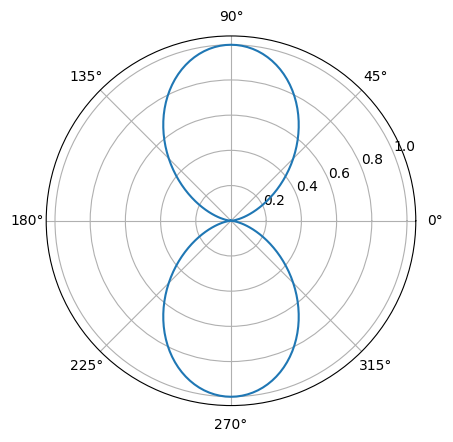

In [13]:
nsteps = 100
theta = np.arange(0.0,2*np.pi,np.pi/nsteps,dtype=np.float64)
Field = (1.0 - np.power(np.cos(theta),2))
plt.polar(theta,Field)

In this case the ring would be along the 90-270 axis for the electic field, and along the 0-180 axis for the magnetic field. 

Lets now see the dependence of the input impedance on the radius, can we ever get it matched without
killing the pattern? 

In [19]:
F0 = 2.5e9 # Hz
W0 = F0 * 2*constants.pi
# then the wavelength is:
Lambda = constants.c/F0
print('Free space Frequency: ', F0, ' Wavelength: ', Lambda, ' meters')
R_Loop = Lambda/(2*constants.pi)
print('Wavelength R = ', R_Loop,' meters')
r = np.arange(0.001, R_Loop, 0.001)
Gauge18_d = 1.02     # mm
r_wire = Gauge18_d/2 * 1.0e-3   # meters
L_Loop = Inductance(1, r, r_wire)

Free space Frequency:  2500000000.0  Wavelength:  0.1199169832  meters
Wavelength R =  0.019085380636947768  meters


Text(0, 0.5, 'Inductance in nH')

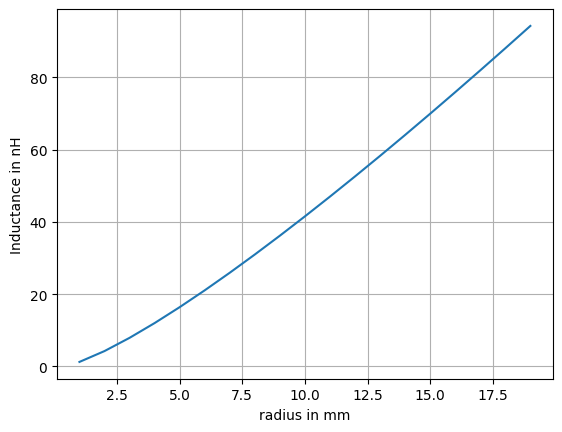

In [22]:
plt.plot(r*1000, L_Loop*1.0e9)
plt.grid()
plt.xlabel('radius in mm')
plt.ylabel('Inductance in nH')

Text(0, 0.5, 'reactance in ohms')

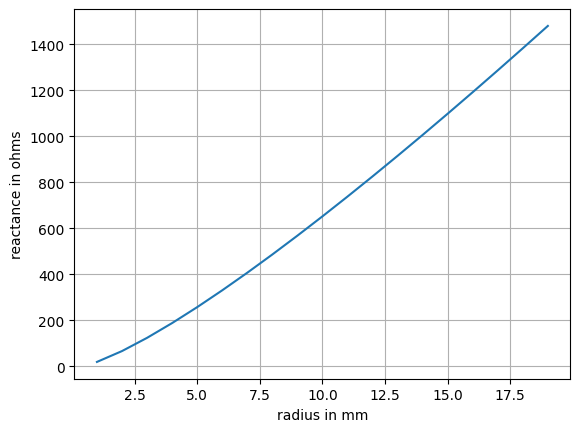

In [25]:
# and Z
Z = W0 * L_Loop  # Roughly
plt.plot(r*1000.0, Z)
plt.grid()
plt.xlabel('radius in mm')
plt.ylabel('reactance in ohms')

Ok in the very small radius this is a decent impedance match. 

Text(0, 0.5, 'reactance in ohms')

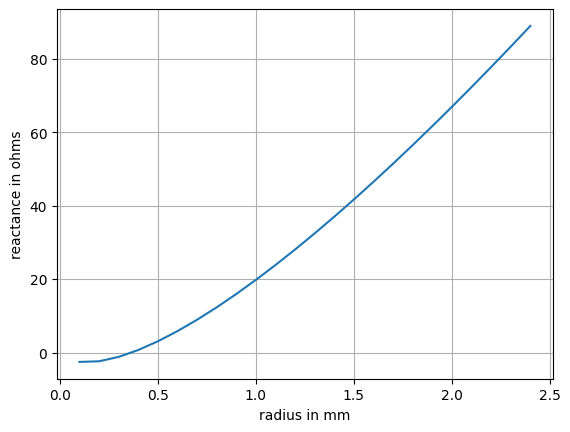

In [26]:
# Look in the small domain. 
r = np.arange(1.0e-4, 2.5e-3, 1.0e-4)
L_Loop = Inductance(1, r, r_wire)
# and Z
Z = W0 * L_Loop  # Roughly
plt.plot(r*1000.0, Z)
plt.grid()
plt.xlabel('radius in mm')
plt.ylabel('reactance in ohms')

So lock down the radius at 1.75mm and look again


In [29]:
L_Loop = Inductance(1, 1.75e-3, r_wire)
print('Loop inductance: ', L_Loop)
# evaluate C for resonance
C_Ext = 1.0/(W0*W0*L_Loop)
print('External capacitance to tune inductor to charactistic frequency: ', C_Ext, ' Farads')

Loop inductance:  3.43590119359167e-09
External capacitance to tune inductor to charactistic frequency:  1.179558758340465e-12  Farads


My concern is that this is a very small loop which might have difficulty in alignment. Additionally, the magnetic field pattern will basically be up and down and very narrow. However, it should have a relatively uniform field with a rather flat dz. 